# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt 
# Importar librerías



### Cargar Dataset

In [18]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [19]:
df.head() # mostrar las primeras 5 filas


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 'nivel_ingreso'
- 'visitas_mes'
- 'gasto_publicidad_dirigida'
- 'satisfaccion'
- 'miembro_premium' (Binaria)
- 'abandono' (Binaria)
- 'ingreso_anual'



La mayoría de estas variables presentan tipos de datos adecuados.  
La columna 'edad' tiene formato de número con decimales, es mejor si se transforma en entero. 


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [20]:
df['tipo_dispositivo'] = df['tipo_dispositivo'].astype('category')
df['region'] = df['region'].astype('category') # Corregir el tipo de dato a 'category'


In [21]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   id_cliente                 15000 non-null  object  
 1   edad                       15000 non-null  float64 
 2   nivel_ingreso              15000 non-null  float64 
 3   visitas_mes                15000 non-null  int64   
 4   compras_mes                15000 non-null  int64   
 5   gasto_publicidad_dirigida  15000 non-null  float64 
 6   satisfaccion               15000 non-null  float64 
 7   miembro_premium            15000 non-null  int64   
 8   abandono                   15000 non-null  int64   
 9   tipo_dispositivo           15000 non-null  category
 10  region                     15000 non-null  category
 11  ingreso_anual              15000 non-null  float64 
dtypes: category(2), float64(5), int64(4), object(1)
memory usage: 1.2+ MB


#### Explorar variables numéricas

In [22]:

print(df.describe())
# Estadísticas descriptivas de variables numéricas



               edad  nivel_ingreso   visitas_mes   compras_mes  \
count  15000.000000   15000.000000  15000.000000  15000.000000   
mean      38.262400   30019.704782     10.029000      1.206467   
std       11.492378    9833.166305      3.158189      1.105284   
min       18.000000    8000.000000      1.000000      0.000000   
25%       30.000000   23127.097500      8.000000      0.000000   
50%       38.000000   30023.745000     10.000000      1.000000   
75%       46.000000   36768.440000     12.000000      2.000000   
max       75.000000   74790.840000     25.000000      8.000000   

       gasto_publicidad_dirigida  satisfaccion  miembro_premium      abandono  \
count               15000.000000  15000.000000     15000.000000  15000.000000   
mean                   20.149301      3.603693         0.139267      0.150733   
std                    10.880724      0.685300         0.346236      0.357801   
min                     0.000000      1.000000         0.000000      0.000000   


✍️ **Comentario**:   

Diagnóstico inicial de variables numéricas: 

Todas las columnas tienen 15,000 filas por lo que están completas.

- `edad` — Promedio (38.2) y la medición al 50% de los datos (38) son muy similares, los valores mínimos (18) y máximos (75) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura. 
- 'nivel_ingreso' — Promedio (30019.70) y la medición al 50% de los datos (30023.74) son muy similares, los valores mínimos (8000) y máximos (74790.84) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura.
- 'visitas_mes' — Promedio (10) y la medición al 50% de los datos (10) son muy similares, los valores mínimos (1) y máximos (25) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura.
- 'compras_mes' — Promedio (1.2) y la medición al 50% de los datos (1) son muy similares, los valores mínimos (0) y máximos (8) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura.
- 'gasto_publicidad_dirigida' — Promedio (20.14) y la medición al 50% de los datos (19.73) son muy similares, los valores mínimos (0) y máximos (75.5) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura.
- 'satisfaccion' — Promedio (3.6) y la medición al 50% de los datos (3.6) son muy similares, los valores mínimos (1) y máximos (5) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura.
- 'miembro_premium' — Es una columna binaria por lo que requiere otro tipo de análisis.
- 'abandono' - Es una columna binaria por lo que requiere otro tipo de análisis.
- 'ingreso_anual' — Promedio (36.59) y la medición al 50% de los datos (30.70) son muy similares, los valores mínimos (0) y máximos (244.69) se encuentran dentro de rangos normales. Esto no da señales de alarmas para considerar Outliers o errores de captura. 

#### Explorar variables binarias

In [23]:

columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(f"Valores únicos en '{col}': {df[col].unique()}") # Verificar que cada columna tenga únicamente dos valores posibles

print("--- Distribución de Miembro Premium ---")
print(df['miembro_premium'].value_counts(normalize=True) * 100)

print("\n--- Tasa de Abandono ---")
print(df['abandono'].value_counts(normalize=True) * 100) #Distribución porcentual de cada valor en las columnas. 


Valores únicos en 'miembro_premium': [0 1]
Valores únicos en 'abandono': [0 1]
--- Distribución de Miembro Premium ---
0    86.073333
1    13.926667
Name: miembro_premium, dtype: float64

--- Tasa de Abandono ---
0    84.926667
1    15.073333
Name: abandono, dtype: float64


In [24]:
# Comparativa de métricas de compra según tipo de membresía
comparativa_compras = df.groupby('miembro_premium')[['compras_mes', 'ingreso_anual']].agg(
    ['mean', 'median', 'std', 'count']
).round(2)

# Renombrar el índice para mayor claridad gráfica (0 = Estándar, 1 = Premium)
comparativa_compras.index = ['Estándar (0)', 'Premium (1)']

print("=== Comparativa de Compras e Ingresos: Estándar vs Premium ===")
print(comparativa_compras)

=== Comparativa de Compras e Ingresos: Estándar vs Premium ===
             compras_mes                     ingreso_anual                \
                    mean median   std  count          mean median    std   
Estándar (0)        1.20      1  1.11  12911         35.30  29.95  33.20   
Premium (1)         1.22      1  1.08   2089         44.58  37.70  40.68   

                     
              count  
Estándar (0)  12911  
Premium (1)    2089  


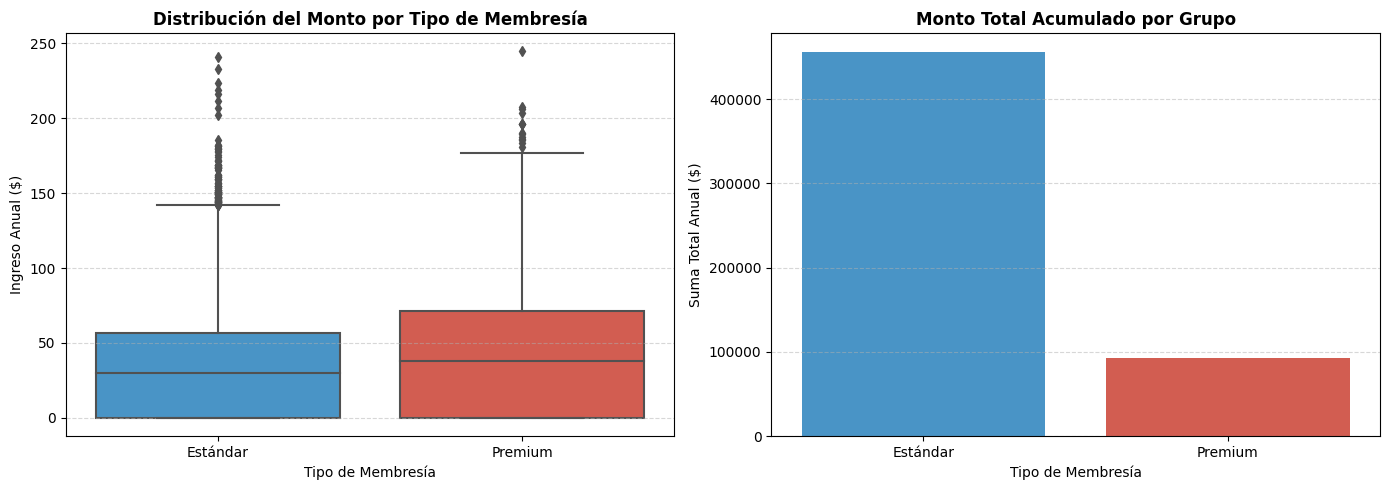

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Crear una columna con etiquetas legibles para los gráficos
df['tipo_membresia'] = df['miembro_premium'].map({0: 'Estándar', 1: 'Premium'})

# Configurar el lienzo con dos gráficos secundarios (subplots)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GRÁFICO 1: Distribución y dispersión (Boxplot) ---
sns.boxplot(
    data=df, 
    x='tipo_membresia', 
    y='ingreso_anual', 
    palette=['#3498db', '#e74c3c'], 
    ax=axes[0]
)
axes[0].set_title('Distribución del Monto por Tipo de Membresía', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tipo de Membresía', fontsize=10)
axes[0].set_ylabel('Ingreso Anual ($)', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# --- GRÁFICO 2: Suma total acumulada (Barplot) ---
total_por_membresia = df.groupby('tipo_membresia')['ingreso_anual'].sum().reset_index()

sns.barplot(
    data=total_por_membresia, 
    x='tipo_membresia', 
    y='ingreso_anual', 
    palette=['#3498db', '#e74c3c'], 
    ax=axes[1]
)
axes[1].set_title('Monto Total Acumulado por Grupo', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tipo de Membresía', fontsize=10)
axes[1].set_ylabel('Suma Total Anual ($)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Ajustar diseño general y mostrar
plt.tight_layout()
plt.show()

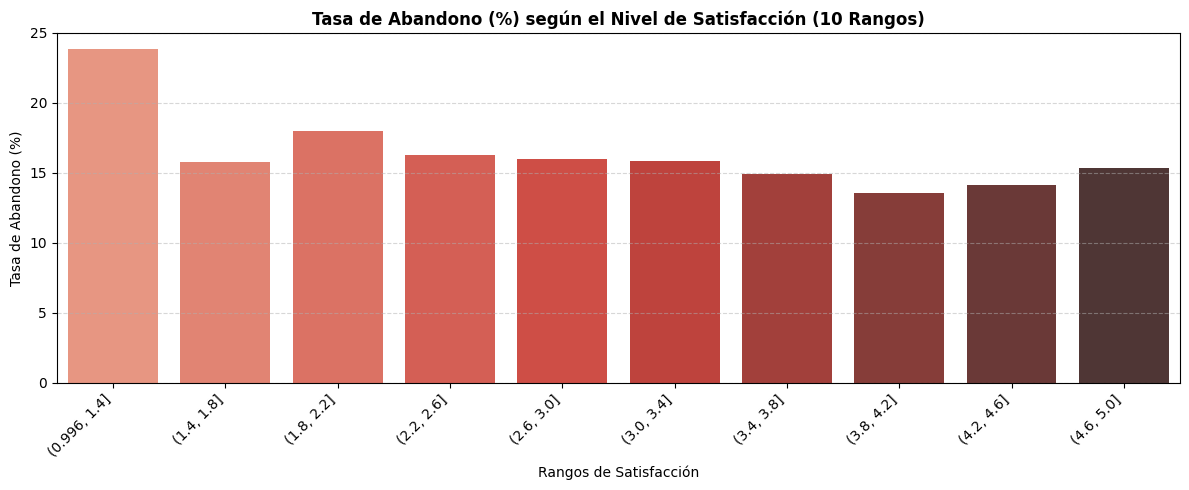

In [25]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Dividir la satisfacción en 10 intervalos (bins) iguales
df['satisfaccion_bin'] = pd.cut(df['satisfaccion'], bins=10)

# Calcular la tasa de abandono por cada uno de los 10 rangos
tasa_abandono_sat = df.groupby('satisfaccion_bin', observed=False)['abandono'].mean().reset_index()
tasa_abandono_sat['tasa_abandono_pct'] = tasa_abandono_sat['abandono'] * 100

# Convertir los intervalos a string para que las etiquetas se muestren ordenadas y limpias en el eje X
tasa_abandono_sat['satisfaccion_bin_str'] = tasa_abandono_sat['satisfaccion_bin'].astype(str)

# 2. Crear el gráfico de barras
plt.figure(figsize=(12, 5))
sns.barplot(
    data=tasa_abandono_sat, 
    x='satisfaccion_bin_str', 
    y='tasa_abandono_pct', 
    palette='Reds_d'
)

plt.title('Tasa de Abandono (%) según el Nivel de Satisfacción (10 Rangos)', fontsize=12, fontweight='bold')
plt.xlabel('Rangos de Satisfacción', fontsize=10)
plt.ylabel('Tasa de Abandono (%)', fontsize=10)
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para que no se encimen
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

✍️ **Comentario**:

Diagnóstico inicial de variables binarias: 

Ambas columnas presentan 2 valores únicos: 0 y 1 


- `miembro_premium` — El 86% de los usuarios no son miembros "Premium", mientras que el 14% restante si lo son. 
- `abandono` — El 15% de los usuarios han abandonado, mientras que el 85% restante se mantienen activos. 


#### Explorar variables categóricas

In [26]:
columnas_categoricas = ['tipo_dispositivo', 'region']


print("=== Número de valores únicos por variable categórica y binaria ===")
for col in columnas_categoricas:
    unicos = df[col].nunique()
    print(f"Columna '{col}': {unicos} valores únicos -> {df[col].unique()}")  # Verificar el número de valores únicos por variable categórica


=== Número de valores únicos por variable categórica y binaria ===
Columna 'tipo_dispositivo': 3 valores únicos -> ['móvil', 'tablet', 'escritorio']
Categories (3, object): ['móvil', 'tablet', 'escritorio']
Columna 'region': 4 valores únicos -> ['norte', 'sur', 'este', 'oeste']
Categories (4, object): ['norte', 'sur', 'este', 'oeste']


In [27]:
print("=== Distribución detallada ===")
for col in columnas_categoricas:
    print(f"\nDistribución en '{col}':")
    conteo = df[col].value_counts(dropna=False)
    porcentaje = df[col].value_counts(normalize=True, dropna=False) * 100
    
    distribucion_df = pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porcentaje})
    print(distribucion_df) # Explorar variables categóricas y cómo se distribuyen


=== Distribución detallada ===

Distribución en 'tipo_dispositivo':
            Cantidad  Porcentaje (%)
móvil           9818       65.453333
escritorio      3720       24.800000
tablet          1462        9.746667

Distribución en 'region':
       Cantidad  Porcentaje (%)
norte      4395           29.30
oeste      3810           25.40
sur        3726           24.84
este       3069           20.46


✍️ **Comentario**:

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — El más usado por mucho es el móvil (9,818 - 65.45%) Seguido de escritorio (3,720 - 24.8%) y el menos usado es la tables (1,462 - 9.7%)
- 'region' - La que tiene la mayoria de tráfico es la region norte (4,395 - 29.3%) casi igual número tiene oeste (3,810 - 25.4), poco abajo está sur (3,069 - 24.84%) y la más baja es este (3,069 - 20.46%)

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

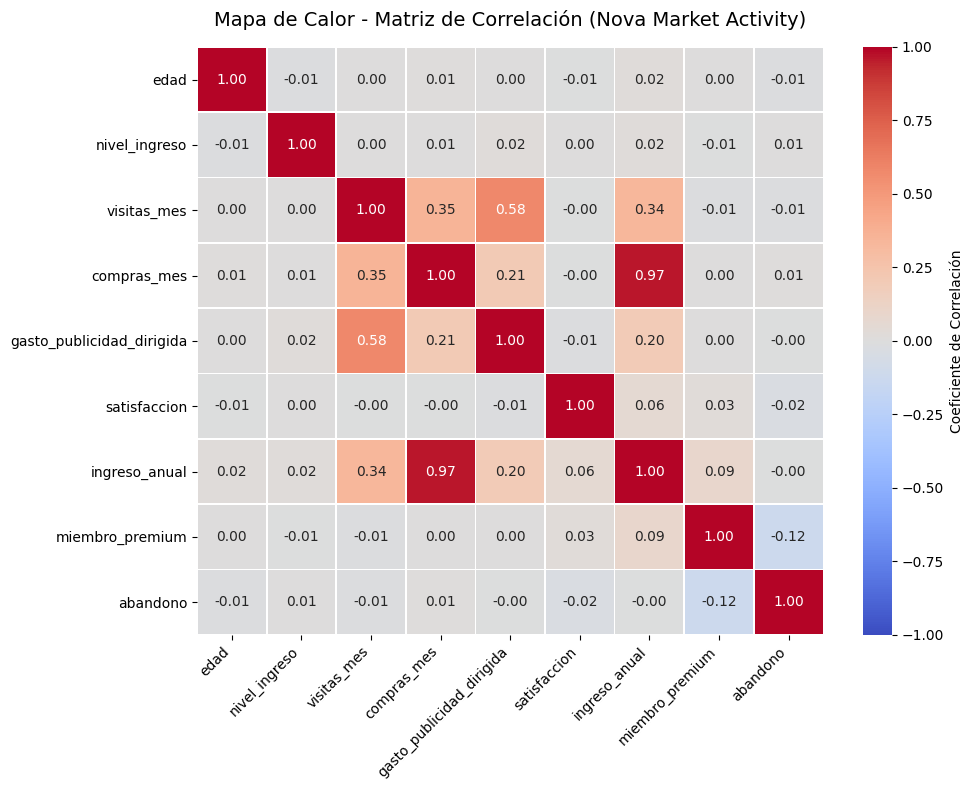

In [28]:
# Columnas numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
    'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual', 
    'miembro_premium', 'abandono']

# Matriz de correlación Pearson
matriz_corr = df[columnas_numericas].corr('pearson')

# Mapa de calor 
plt.figure(figsize=(10, 8))
sns.heatmap( matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Coeficiente de Correlación'})

plt.title('Mapa de Calor - Matriz de Correlación (Nova Market Activity)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


✍️ **Comentario**:


Observaciones generales (Heatmap)  
- Se observa que existen pocas correlaciones que sean significativas para el negocio, a continuación se ordenan de mayor a menor. 


Observaciones respecto a `ingreso_anual`  <-> 'compras_mes' (0.97)
- Es la correlación más alta, sin embargo es insignificante y no representa un hallazgo especial para el negocio ya que a mayor volumen de compras, los ingresos crecen igual, o, dicho de otra forma son sinónimos pero vistos en diferentes periodos de tiempo.
Observación:  'gasto_publicidad_dirigida' <-> 'visitas_mes' (0.58)
- Es la variable significativa más fuerte y supera el .5 por lo que la vemos con más protagonismo.
Observación: 'visitas_mes' <-> 'compras_mes' (0.35)
- Correlación menor a .5 pero sigue siendo relevante para e negocio ya que podrían estar realcionadas.
Observación: 'Ingreso_anual' <-> 'visita_mes' (0.34)
-Es una Correlación significativa pero debemos analizar más al respecto ya que puede ser una mera coincidencia.
Observación: 'ingreso_anual' <-> 'publicidad_dirigida' (0.20)
No es tan relevante como otras, pero merece la pena investigarla más a detalle. 


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

### Scatterplot para pares clave

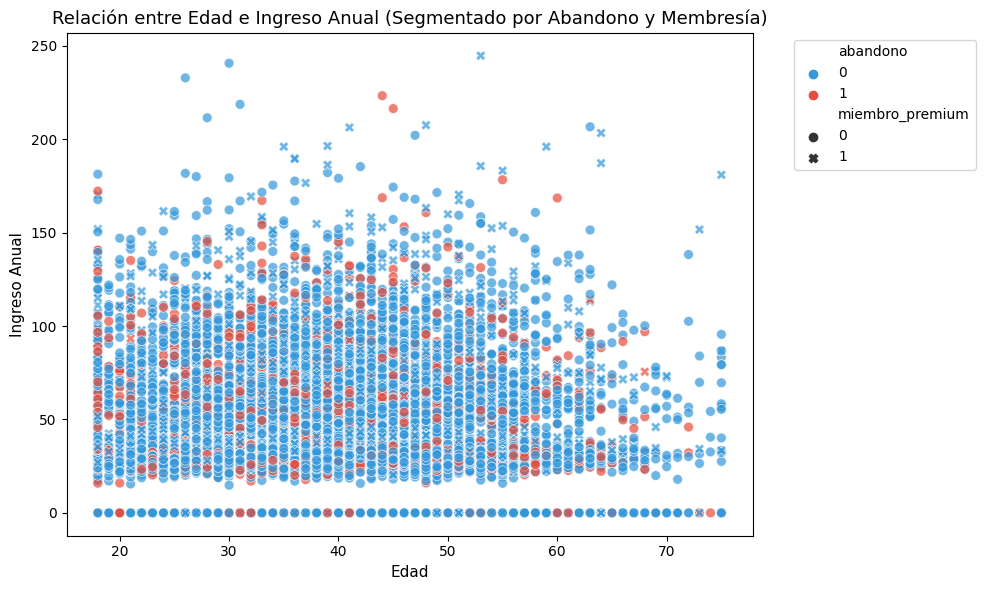

In [29]:

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='edad', y='ingreso_anual', hue='abandono', style='miembro_premium', palette=['#3498db', '#e74c3c'], alpha=0.7, s=50)

plt.title('Relación entre Edad e Ingreso Anual (Segmentado por Abandono y Membresía)', fontsize=13)
plt.xlabel('Edad', fontsize=11)
plt.ylabel('Ingreso Anual', fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
plt.tight_layout()
plt.show() # Visualizar pares de variables con relaciones moderadas o fuertes



=== Pares con correlación moderada o fuerte (Umbral >= 0.2) ===

👉 Relación detectada entre 'visitas_mes' y 'compras_mes': r = 0.35


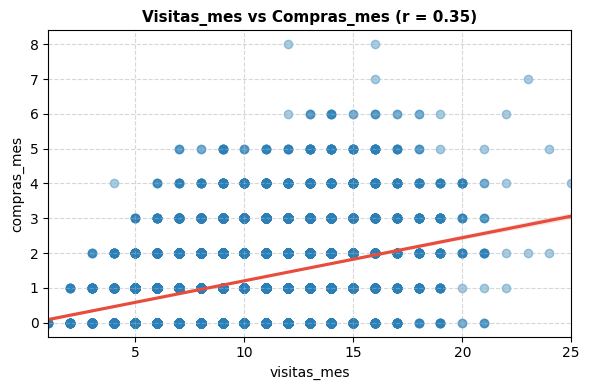

👉 Relación detectada entre 'visitas_mes' y 'gasto_publicidad_dirigida': r = 0.58


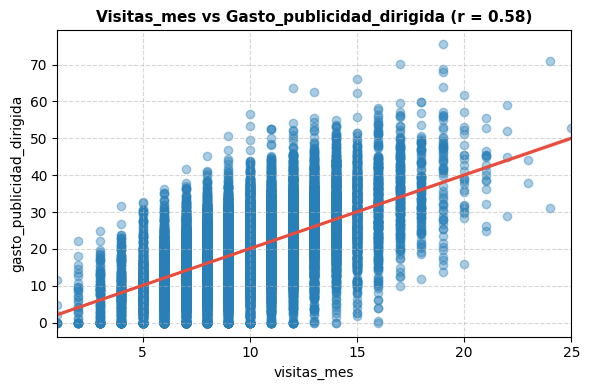

👉 Relación detectada entre 'compras_mes' y 'gasto_publicidad_dirigida': r = 0.21


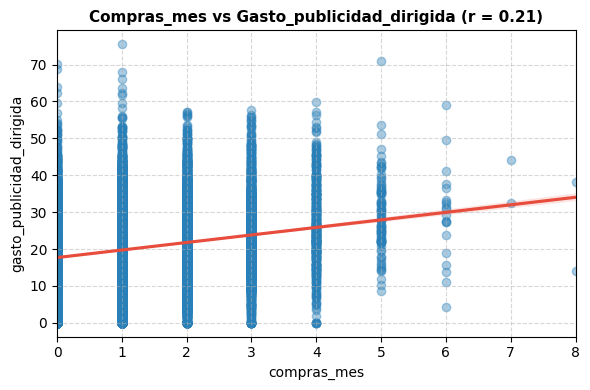

👉 Relación detectada entre 'visitas_mes' y 'ingreso_anual': r = 0.34


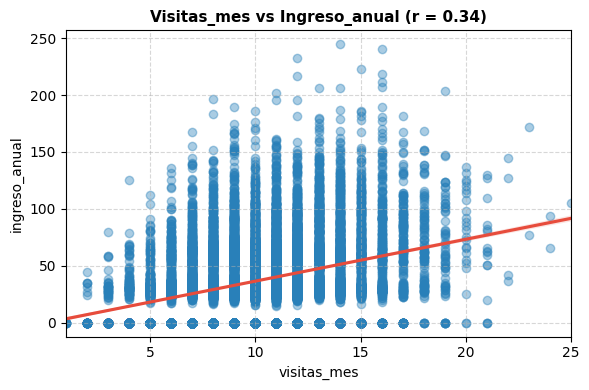

👉 Relación detectada entre 'compras_mes' y 'ingreso_anual': r = 0.97


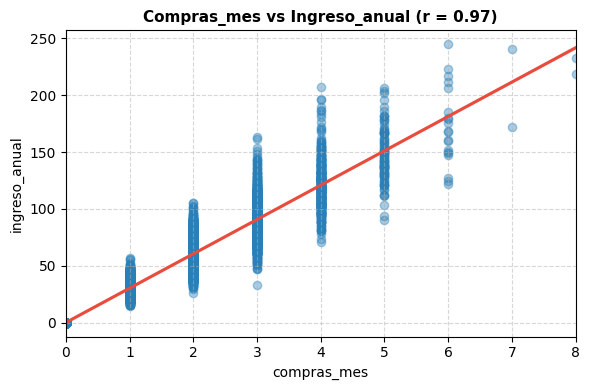

In [30]:
# 1. Seleccionamos las columnas numéricas analizadas en el heatmap
columnas_numericas = [
    'edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 
    'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual'
]

# 2. Obtenemos la matriz de correlación
matriz_corr = df[columnas_numericas].corr()

# 3. Definimos un umbral para considerar la relación como moderada o fuerte
umbral = 0.2

print(f"=== Pares con correlación moderada o fuerte (Umbral >= {umbral}) ===\n")

# 4. Recorremos el triángulo inferior de la matriz para evitar duplicados y auto-correlaciones
for i in range(len(matriz_corr.columns)):
    for j in range(i):
        coef_corr = matriz_corr.iloc[i, j]
        
        # Si la correlación supera el umbral (en positivo o negativo)
        if abs(coef_corr) >= umbral:
            var1 = matriz_corr.columns[i]
            var2 = matriz_corr.columns[j]
            
            print(f"👉 Relación detectada entre '{var2}' y '{var1}': r = {coef_corr:.2f}")
            
            # 5. Generamos el gráfico de dispersión (scatterplot) con línea de tendencia (regplot)
            plt.figure(figsize=(6, 4))
            sns.regplot(
                data=df, 
                x=var2, 
                y=var1,
                scatter_kws={'alpha': 0.4, 'color': '#2980b9'}, # Puntos semitransparentes
                line_kws={'color': '#e74c3c'}                  # Línea de tendencia roja
            )
            
            plt.title(f'{var2.capitalize()} vs {var1.capitalize()} (r = {coef_corr:.2f})', fontsize=11, fontweight='bold')
            plt.xlabel(var2, fontsize=10)
            plt.ylabel(var1, fontsize=10)
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.tight_layout()
            plt.show()

✍️ **Comentario**:   
Análisis de variable 'visita_mes' contra otras variables ya que son las más relevantes: 

Observaciones iniciales (Scatterplot)

**'compras_mes'**
- Dirección positiva
- rho : 0.35
- Se observan datos muy dispersos sin embargo nada que nos haga sospechar de Outliers.

**'gasto_publicidad_dirigida'**
- Dirección positiva
- rho : 0.58
- Los datos no son tan dispersos, siguen la linea de tendencia y la desviación estándar es muy baja.

**'ingreso_anual'**
- Dirección positiva
- rho : 0.34
- Se observan datos muy dispersos sin embargo nada que nos haga sospechar de Outliers.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [31]:

matriz_spearman = df[columnas_numericas].corr(method='spearman')

print("=== Matriz de Correlación de Spearman ===")
print(matriz_spearman)
 # Calcular correlación entre variables relevantes


=== Matriz de Correlación de Spearman ===
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.007775     0.005205     0.015630   
nivel_ingreso             -0.007775       1.000000     0.001420     0.009004   
visitas_mes                0.005205       0.001420     1.000000     0.332943   
compras_mes                0.015630       0.009004     0.332943     1.000000   
gasto_publicidad_dirigida  0.002869       0.015393     0.559267     0.192511   
satisfaccion              -0.007590       0.005243    -0.001305    -0.002006   
ingreso_anual              0.016097       0.025017     0.320954     0.967482   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.002869     -0.007590   
nivel_ingreso                               0.015393      0.005243   
visitas_mes                                 0.559267     -0.001305   
compras_mes                          

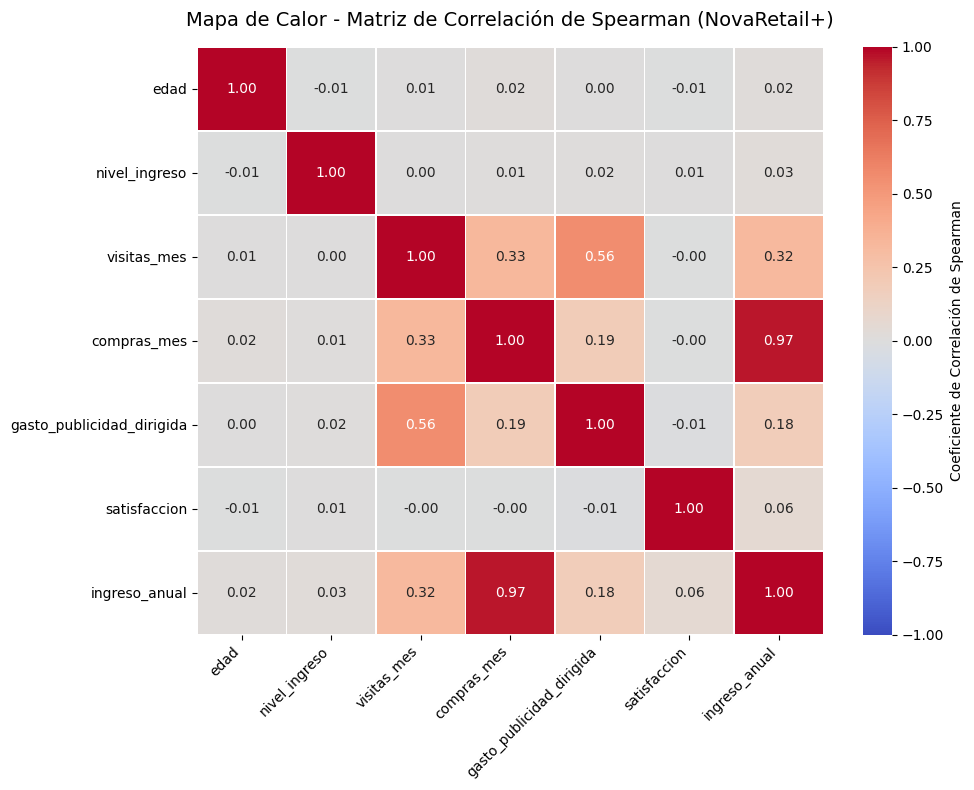

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor para la matriz de Spearman
sns.heatmap(
    matriz_spearman, 
    annot=True,              # Mostrar los valores numéricos en cada celda
    fmt='.2f',               # Formato de dos decimales
    cmap='coolwarm',         # Paleta de colores (divergente)
    vmin=-1, 
    vmax=1,                  # Rango de correlación de -1 a 1
    linewidths=0.5,          # Líneas divisorias entre celdas
    cbar_kws={'label': 'Coeficiente de Correlación de Spearman'}
)

# Títulos y formato visual
plt.title('Mapa de Calor - Matriz de Correlación de Spearman (NovaRetail+)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

In [33]:

matriz_pearson = df[columnas_numericas].corr(method='pearson')

print("=== Matriz de Correlación de Pearson ===")
print(matriz_pearson)# Calcular correlación entre variables relevantes



=== Matriz de Correlación de Pearson ===
                               edad  nivel_ingreso  visitas_mes  compras_mes  \
edad                       1.000000      -0.009003     0.004998     0.014971   
nivel_ingreso             -0.009003       1.000000     0.001060     0.007309   
visitas_mes                0.004998       0.001060     1.000000     0.353844   
compras_mes                0.014971       0.007309     0.353844     1.000000   
gasto_publicidad_dirigida  0.000062       0.016834     0.578947     0.207528   
satisfaccion              -0.006963       0.002301    -0.003179    -0.003542   
ingreso_anual              0.017496       0.017446     0.337147     0.967149   

                           gasto_publicidad_dirigida  satisfaccion  \
edad                                        0.000062     -0.006963   
nivel_ingreso                               0.016834      0.002301   
visitas_mes                                 0.578947     -0.003179   
compras_mes                           

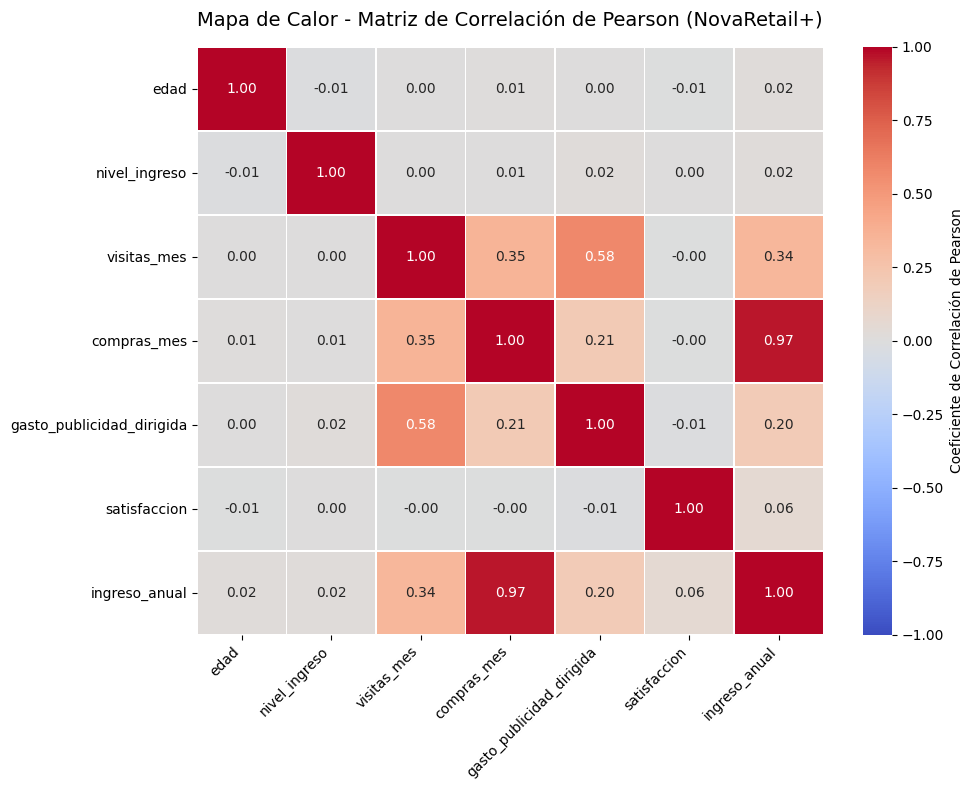

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño de la figura
plt.figure(figsize=(10, 8))

# Crear el mapa de calor para la matriz de Pearson
sns.heatmap(
    matriz_pearson, 
    annot=True,              # Mostrar los valores numéricos en cada celda
    fmt='.2f',               # Formato de dos decimales
    cmap='coolwarm',         # Paleta de colores (divergente)
    vmin=-1, 
    vmax=1,                  # Rango de correlación de -1 a 1
    linewidths=0.5,          # Líneas divisorias entre celdas
    cbar_kws={'label': 'Coeficiente de Correlación de Pearson'}
)

# Títulos y formato visual
plt.title('Mapa de Calor - Matriz de Correlación de Pearson (NovaRetail+)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

✍️ **Comentario**: Se muestran correlaciones con el método de Spearman y de Pearson - ambos muestran resultados muy similares. A continuación el detalle: 



Observaciones de correlación
**Visitas_mes** con:


**gasto_publicidad_dirigida**
- Correlación con S (spearman) = 0.56 y P (pearson) = 0.58
- Ambos métodos muestran una correlación fuerte mayor a 0.50
- En el satterplot también se ve una tendencia positiva entre estas dos variables.  

**compras_mes**

- Correlación con S = 0.33 y P = 0.35
- Ambos métodos muestran una correlación cercana al 0.30
- En el satterplot se ve una tendencia positiva entre estas dos variables aunque con datos dispersos.
- Aunque no es la correlación más fuerte, si puede ser significativa y digna de ser tomada en cuenta para decisiones del negocio.

**ingreso_anual**

- Correlación con S = 0.32 y P = 0.34
- Ambos métodos muestran una correlación cercana al 0.30
- En el satterplot se ve una tendencia positiva entre estas dos variables aunque con datos dispersos.
- Aunque no es la correlación más fuerte, si puede ser significativa y digna de ser tomada en cuenta para decisiones del negocio.



Observaciones de correlación
**gasto_publicidad_dirigida** con:

**compras_mes** 

- Correlación con S = 0.19 y P = 0.20
- Ambos métodos muestran una correlación cercana al 0.20
- En el satterplot se ve una tendencia ligeramente positiva entre estas dos variables aunque con bastantes datos dispersos.
- Debemos analizar esta variable más a detalle ya que puede ser significativa o ser una mera coincidencia. 


### Punto-biserial

In [35]:

from scipy.stats import pointbiserialr

# Ejemplo: Relación entre 'miembro_premium' e 'ingreso_anual'
corr_biserial, p_value = pointbiserialr(df['miembro_premium'], df['ingreso_anual'])
print(f"Correlación Punto-Biserial (miembro_premium vs ingreso_anual): r = {corr_biserial:.4f} (p-value: {p_value:.4e})")

# Ejemplo: Relación entre 'abandono' y 'satisfaccion'
corr_biserial_2, p_value_2 = pointbiserialr(df['abandono'], df['satisfaccion'])
print(f"Correlación Punto-Biserial (abandono vs satisfaccion): r = {corr_biserial_2:.4f} (p-value: {p_value_2:.4e})") # Calcular correlación entre variables relevantes



Correlación Punto-Biserial (miembro_premium vs ingreso_anual): r = 0.0931 (p-value: 3.0943e-30)
Correlación Punto-Biserial (abandono vs satisfaccion): r = -0.0238 (p-value: 3.5110e-03)


=== Matriz de Correlación Punto-Biserial ===
                     edad  visitas_mes  compras_mes  \
miembro_premium  0.004605    -0.012657     0.003431   
abandono        -0.011500    -0.008943     0.008291   

                 gasto_publicidad_dirigida  satisfaccion  
miembro_premium                   0.002721      0.025734  
abandono                         -0.004586     -0.023833  


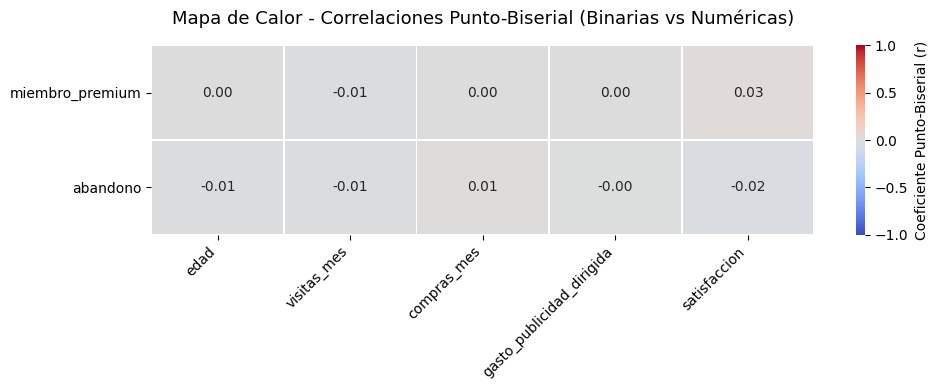

In [36]:
from scipy.stats import pointbiserialr
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Definir las variables binarias y las continuas a relacionar
vars_binarias = ['miembro_premium', 'abandono']
vars_continuas = [
    'edad', 
    'visitas_mes', 
    'compras_mes', 
    'gasto_publicidad_dirigida', 
    'satisfaccion'
]

# 2. Crear una matriz vacía para almacenar los coeficientes punto-biserial (r)
matriz_biserial = pd.DataFrame(index=vars_binarias, columns=vars_continuas)

# 3. Calcular la correlación punto-biserial para cada par
for bin_col in vars_binarias:
    for cont_col in vars_continuas:
        # pointbiserialr devuelve un objeto con el coeficiente 'statistic' (r) y 'pvalue'
        corr, _ = pointbiserialr(df[bin_col], df[cont_col])
        matriz_biserial.loc[bin_col, cont_col] = corr

# Convertir la matriz resultante a valores numéricos
matriz_biserial = matriz_biserial.astype(float)

print("=== Matriz de Correlación Punto-Biserial ===")
print(matriz_biserial)

# 4. Visualizar los resultados mediante un mapa de calor (Heatmap)
plt.figure(figsize=(10, 4))
sns.heatmap(
    matriz_biserial, 
    annot=True,              # Mostrar los valores numéricos
    fmt='.2f',               # Formato de dos decimales
    cmap='coolwarm',         # Paleta de colores divergente
    vmin=-1, 
    vmax=1,                  # Rango estándar de -1 a 1 para correlaciones
    linewidths=0.5,          # Líneas divisorias
    cbar_kws={'label': 'Coeficiente Punto-Biserial (r)'}
)

plt.title('Mapa de Calor - Correlaciones Punto-Biserial (Binarias vs Numéricas)', fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

✍️ **Comentario**: 

Observaciones Punto-biserial: Relación de 'miembro_premium' y 'abandono' (columnas biseriales) con 'edad', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida' y 'satisfaccion'

La correlación entre todas las variables es demasiado débil para poder afirmar que son significativas o están relacionadas entre si. 

### V de Cramér

=== Matriz de Asociación (V de Cramér) ===
                  tipo_dispositivo   region  miembro_premium  abandono
tipo_dispositivo          1.000000  0.00000         0.015993  0.000000
region                    0.000000  1.00000         0.000000  0.006170
miembro_premium           0.015993  0.00000         0.999722  0.119945
abandono                  0.000000  0.00617         0.119945  0.999740


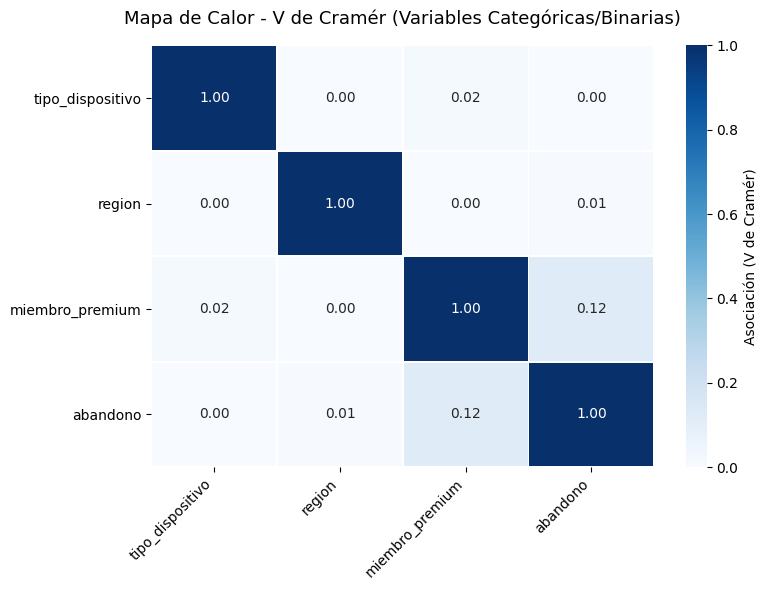

In [37]:
import scipy.stats as stats

# 1. Definir la función para calcular la V de Cramér
def cramers_v(cat1, cat2):
    tabla_contingencia = pd.crosstab(cat1, cat2)
    chi2 = stats.chi2_contingency(tabla_contingencia)[0]
    n = tabla_contingencia.sum().sum()
    phi2 = chi2 / n
    r, k = tabla_contingencia.shape
    
    # Corrección de bias
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    
    denominador = min(kcorr - 1, rcorr - 1)
    if denominador == 0:
        return 0.0
    return np.sqrt(phi2corr / denominador)

# 2. Definir las variables categóricas y binarias a analizar
vars_cat_bin = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

# 3. Crear una matriz vacía para almacenar los resultados
matriz_cramers = pd.DataFrame(index=vars_cat_bin, columns=vars_cat_bin)

# 4. Calcular la V de Cramér para cada par de variables
for col1 in vars_cat_bin:
    for col2 in vars_cat_bin:
        matriz_cramers.loc[col1, col2] = cramers_v(df[col1], df[col2])

# Convertir la matriz a valores numéricos
matriz_cramers = matriz_cramers.astype(float)

print("=== Matriz de Asociación (V de Cramér) ===")
print(matriz_cramers)

# 5. Visualizar los resultados con un mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_cramers, 
    annot=True, 
    fmt='.2f', 
    cmap='Blues', 
    vmin=0, 
    vmax=1, 
    linewidths=0.5, 
    cbar_kws={'label': 'Asociación (V de Cramér)'}
)

plt.title('Mapa de Calor - V de Cramér (Variables Categóricas/Binarias)', fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


✍️ **Comentario**:

Observaciones V de Cramér
Las asociaciones son muy débiles para tomarlas en cuenta, la relación más fuerte es la de 'miembros_premium' con 'abandono' pero tan solo es del 0.12 


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgos 

## Hallazgo 1 — Usuarios Premium y Tasa de Abandono

El 86% de los usuarios son Regulares, solamente el 14% son usuarios Premium. Encontramos que el hecho de que los usuarios sean o no sean Premium, no crea una brecha en el número de compras que realizan los usuarios ni en el monto gastado en el año. Mientra que los Premium tienen un promedio de compras de 1.22 y un monto promedio de 35, los usuarios Regulares tienen un promedio de 1.20 compras y un monnto promedio de 30. Como vemos son valores muy similares.
Por otra parte la tasa de abandono es del 15%, no encontramos indicadores claros que nos revelen causalidad directa, aunque los usuarios que tienen una satisfacción menor (valores cercanos a 1) tienen ligeramente más abandono aunque no es una gran diferencia. 
Se recomienda revisar funcionalidad de la aplicación.

Particularmente con la tasa de abandono se recomienda revisar factores que puedan estar influyendo en el abandono de los usuarios, interfaz de usuario, facilidad del uso de la aplicación, correcto funcionamiento de la pasarela de pago, entre otras posibilidades. 


### Hallazgo 2 — Tipos de Dispositivo y Regiones

Encontramos que el dispositivo más usado es el móvil (65.45%) con una cantidad de 9,818 usuarios. En segundo lugar está escritorio con el 24% y por último la tablet con 9.7%. 
=== Distribución detallada ===

Distribución en 'tipo_dispositivo':
            Cantidad  Porcentaje (%)
móvil           9818       65.453333
escritorio      3720       24.800000
tablet          1462        9.746667

Por su parte las regiones parcen estar distribuidas muy equitativamente. La diferencia máxima es poco menos del 9% entre la que tiene más usuarios y la que tiene menos. 

Distribución en 'region':
       Cantidad  Porcentaje (%)
norte      4395           29.30
oeste      3810           25.40
sur        3726           24.84
este       3069           20.46



### Hallazgo 3 - Variables y correlaciones más relevantes.

Encontramos que la variable 'visita_mes' es la que suele ser la más importante combinada con otras variables, particularmente con 'compras_mes', 'gasto_publicidad_dirigida' e 'ingreso_anual'. Otra correlación importante fue 'gasto_publicidad_dirigida' con 'compras_mes'.

Observaciones iniciales Scatterplot 'visitas_mes' correlación con:

**'gasto_publicidad_dirigida'**
- Dirección positiva
- rho : 0.58
- Los datos no son tan dispersos, siguen la linea de tendencia y la desviación estándar es muy baja.
**'compras_mes'**
- Dirección positiva
- rho : 0.35
- Se observan datos muy dispersos sin embargo nada que nos haga sospechar de Outliers.
**'ingreso_anual'**
- Dirección positiva
- rho : 0.34
- Se observan datos muy dispersos sin embargo nada que nos haga sospechar de Outliers.


Observaciones con el método de Spearman y de Pearson - ambos muestran resultados muy similares. A continuación el detalle: 

Observaciones de correlación **Visitas_mes** con:

**gasto_publicidad_dirigida**
- Correlación con S (spearman) = 0.56 y P (pearson) = 0.58
- Ambos métodos muestran una correlación fuerte mayor a 0.50
- En el satterplot también se ve una tendencia positiva entre estas dos variables.  

**compras_mes**
- Correlación con S = 0.33 y P = 0.35
- Ambos métodos muestran una correlación cercana al 0.30
- En el satterplot se ve una tendencia positiva entre estas dos variables aunque con datos dispersos.
- Aunque no es la correlación más fuerte, si puede ser significativa y digna de ser tomada en cuenta para decisiones del negocio.

**ingreso_anual**
- Correlación con S = 0.32 y P = 0.34
- Ambos métodos muestran una correlación cercana al 0.30
- En el satterplot se ve una tendencia positiva entre estas dos variables aunque con datos dispersos.
- Aunque no es la correlación más fuerte, si puede ser significativa y digna de ser tomada en cuenta para decisiones del negocio.



Observaciones de correlación
**gasto_publicidad_dirigida** con **compras_mes**: 

- Correlación con S = 0.19 y P = 0.20
- Ambos métodos muestran una correlación cercana al 0.20
- En el satterplot se ve una tendencia ligeramente positiva entre estas dos variables aunque con bastantes datos dispersos.
- Debemos analizar esta variable más a detalle ya que puede ser significativa o ser una mera coincidencia. 

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones del análisis**
Aunque el presente estudio correlacional nos otorga una línea base valiosa sobre el comportamiento de los usuarios en NovaRetail+, es necesario reconocer las siguientes limitaciones técnicas y metodológicas:
Ausencia de Causalidad:
Las correlaciones detectadas (por ejemplo, entre el gasto en publicidad dirigida, las visitas mensuales y el ingreso anual) indican asociación estadística, pero no demuestran causalidad. Es posible que exista una variable de confusión no medida (como la propensión natural del usuario a gastar en internet) que impulse tanto las visitas como los ingresos.
Supuestos de Linealidad:
El uso de coeficientes de correlación tradicionales (como Pearson) asume relaciones estrictamente lineales. Comportamientos complejos de los usuarios —como la saturación de anuncios (rendimientos decrecientes en el gasto publicitario) o curvas de satisfacción no lineales frente al abandono— podrían estar subestimados o pasados por alto.
Sesgo de Desbalance de Clases:
Variables clave como miembro_premium (~14% de la base) y abandono (~15%) están desbalanceadas. Esto puede sesgar las métricas de asociación y requerir técnicas de ponderación o muestreo si se planea modelar predictivamente sobre ellas.   

**Próximos pasos y recomendaciones estratégicas**
Para transformar estos hallazgos exploratorios en palancas de crecimiento accionables para el negocio, se proponen las siguientes líneas de acción:
Migración a Modelos Predictivos de Importancia de Variables:
Acción: Implementar algoritmos de Machine Learning supervisado basados en árboles (como Random Forest o XGBoost) para predecir el ingreso_anual y el abandono.
Objetivo: Superar las limitaciones de la correlación bivariada y capturar interacciones no lineales complejas entre el comportamiento del usuario y su valor financiero.
Segmentación de Clientes mediante Clustering (K-Means / DBSCAN):
Acción: Agrupar a los 15,000 usuarios basándose en su frecuencia de visitas, ticket de compra, nivel de ingresos y antigüedad.   
S8 Student Version-Project-NovaRetail.ipynb
Objetivo: Identificar clústeres de "clientes de alto valor" y "clientes en riesgo de abandono" para diseñar campañas de retención hiperpersonalizadas.
Diseño de Experimentos (Pruebas A/B):
Acción: Validar causalidad mediante experimentación controlada. Por ejemplo, asignar aleatoriamente presupuestos diferenciados de gasto_publicidad_dirigida a segmentos similares de usuarios.
Objetivo: Medir el Retorno de Inversión (ROI) real de las campañas en lugar de asumir que a mayor gasto publicitario, mayor ingreso directo.
Desarrollo de un Dashboard Operativo:
Acción: Construir un tablero interactivo (en herramientas como Tableau o Power BI, apoyándonos en nuestras consultas SQL y pipelines de Python/Pandas) que monitoree en tiempo real la salud de la retención y la tasa de conversión premium.